# ROLL NUMBER: G25AIT2138

# Foundations of Vision and Language — Individual Mini CV Project (20 Marks)

**Student Name:** Alok Sahni  
**Roll Number:** G25AIT2138  
**Programme:** PGDAI, School of AI and Data Science, IIT Jodhpur  
**Email:** g25ait2138@iitj.ac.in  

---

## Effect of Blur and Sharpening on Object Detection

- **Dataset:** COCO128 (128 images, 80 classes)
- **Model:** Pretrained YOLO11n (`yolo11n.pt`)
- **Platform:** Google Colab / Local Jupyter
- **Training:** Not required (Frozen inference-only ablation study)

### Project Objectives
1. **Stage 1 — Baseline:** Evaluate YOLO11n on pristine COCO128 images.
2. **Stage 2 — Blur:** Apply a 9×9 Gaussian blur to all images and re-evaluate under identical settings.
3. **Stage 3 — Sharpening:** Apply unsharp masking to restore high-frequency edges and re-evaluate.
4. **Stage 4 — Analysis:** Rigorously compare Precision, Recall, mAP@0.5, and mAP@0.5:0.95 across stages.

## Setup 1 — Install Packages

In [1]:
%pip -q install -U ultralytics pyyaml opencv-python matplotlib pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 53.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 214.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 192.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 14.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.


## Setup 2 — Download COCO128

In [2]:
from pathlib import Path
import urllib.request
import zipfile
import os

# Google Colab → /content/datasets
# Local/Jupyter/GPU server → ~/fvl_datasets
if Path("/content").exists() and os.access("/content", os.W_OK):
    DATA_ROOT = Path("/content/datasets")
else:
    DATA_ROOT = Path.home() / "fvl_datasets"

DATA_ROOT.mkdir(parents=True, exist_ok=True)

zip_path = DATA_ROOT / "coco128.zip"
dataset_dir = DATA_ROOT / "coco128"

if not dataset_dir.exists():
    url = "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip"
    print("Downloading COCO128 to:", zip_path)
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_ROOT)
    print("Download and extraction complete.")
else:
    print("COCO128 dataset verified.")

ORIG_IMAGES = dataset_dir / "images" / "train2017"
ORIG_LABELS = dataset_dir / "labels" / "train2017"
print("Dataset ready at:", dataset_dir)
print("Images:", ORIG_IMAGES, f"({len(list(ORIG_IMAGES.glob('*.jpg')))} images)")
print("Labels:", ORIG_LABELS, f"({len(list(ORIG_LABELS.glob('*.txt')))} label files)")

Download and extraction complete.
Dataset ready at: /content/datasets/coco128
Images: /content/datasets/coco128/images/train2017 (128 images)
Labels: /content/datasets/coco128/labels/train2017 (128 label files)


## Setup 3 — Load Pretrained YOLO11n

In [3]:
from pathlib import Path
import os, yaml, cv2, shutil
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO

if Path("/content").exists() and os.access("/content", os.W_OK):
    PROJECT_ROOT = Path("/content/fvl_project_G25AIT2138")
else:
    PROJECT_ROOT = Path.home() / "fvl_project_G25AIT2138"

PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
print("Project folder:", PROJECT_ROOT)

DEVICE = 0 if torch.cuda.is_available() else 'cpu'
model = YOLO('yolo11n.pt')
print(f"Model loaded: YOLO11n pretrained on COCO ({len(model.names)} classes)")

# Global results dictionary and evaluation configuration
RESULTS = {}
EXAMPLE_FILES = ['000000000009.jpg', '000000000025.jpg', '000000000030.jpg']
VAL_ARGS = dict(imgsz=640, batch=16, device=DEVICE, workers=0, verbose=False, plots=False)

def write_yaml(root_dir, filename):
    config = {
        'path': str(root_dir.resolve()),
        'train': 'images/train2017',
        'val': 'images/train2017',
        'names': {int(k): str(v) for k, v in model.names.items()}
    }
    out_path = PROJECT_ROOT / filename
    with open(out_path, 'w', encoding='utf-8') as f:
        yaml.safe_dump(config, f, sort_keys=False)
    return out_path

def show_and_save_predictions(images_dir, stage_name, save_dir):
    save_dir.mkdir(parents=True, exist_ok=True)
    fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
    for j, name in enumerate(EXAMPLE_FILES):
        img_path = images_dir / name
        res = model.predict(source=str(img_path), imgsz=640, conf=0.25, iou=0.7, device=DEVICE, verbose=False)[0]
        plotted = res.plot()
        cv2.imwrite(str(save_dir / name), plotted)
        axs[j].imshow(cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB))
        axs[j].set_title(f"{stage_name}\n{name} ({len(res.boxes)} det.)", fontsize=10, fontweight='bold')
        axs[j].axis('off')
    plt.suptitle(f"{stage_name} — Prediction Examples", fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

print("Fixed prediction example images:", EXAMPLE_FILES)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Project folder: /content/fvl_project_G25AIT2138
Model loaded: YOLO11n pretrained on COCO (80 classes)
Fixed prediction example images: ['000000000009.jpg', '000000000025.jpg', '000000000030.jpg']


# Stage 1 — Baseline on Original Images

### Your task
1. Prepare a dataset YAML that points to the original COCO128 images and labels.
2. Run `model.val(...)` using the pretrained YOLO11n model.
3. Record only these four metrics: Precision, Recall, mAP@0.5, mAP@0.5:0.95.
4. Save at least **3 prediction examples**.

Evaluating Stage 1: Original / Baseline...
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2615.2±636.3 MB/s, size: 37.6 KB)
val: Scanning /content/datasets/coco128/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 3.3Kit/s 0.0s
val: New cache created: /content/datasets/coco128/labels/train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 14.0it/s 0.6s
                   all        128        929       0.66      0.589       0.67      0.503
Speed: 0.1ms preprocess, 1.4ms inference, 0.0ms loss, 0.4ms postprocess per image

--- STAGE 1 (BASELINE) METRICS ---
Precision     : 0.6599
Recall        : 0.5886
mAP@0.5       : 0.6703
mAP@0.5:0.95  : 0.5026


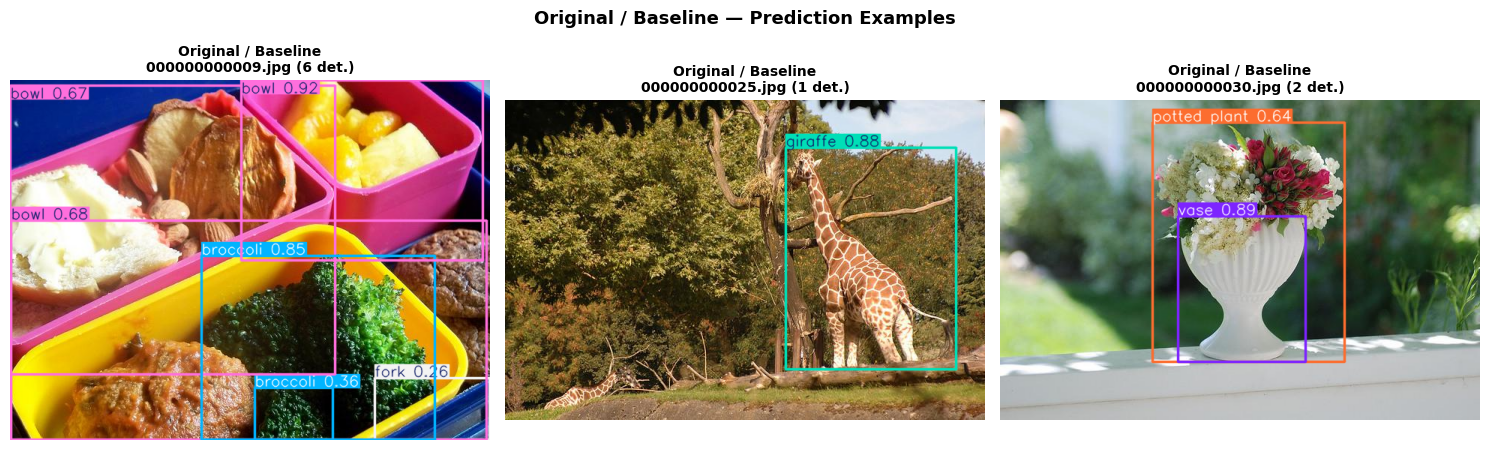

Predictions saved to: /content/fvl_project_G25AIT2138/predictions/original


In [4]:
# STAGE 1 — STUDENT CODE

# 1. Create a dataset YAML for the original COCO128 data.
ORIGINAL_YAML = write_yaml(dataset_dir, 'coco128_original.yaml')

# 2. Run model.val(...).
print('Evaluating Stage 1: Original / Baseline...')
val_results_s1 = model.val(data=str(ORIGINAL_YAML), **VAL_ARGS)

# 3. Print the four required metrics.
RESULTS['Original / Baseline'] = {
    'Precision': float(val_results_s1.box.mp),
    'Recall': float(val_results_s1.box.mr),
    'mAP@0.5': float(val_results_s1.box.map50),
    'mAP@0.5:0.95': float(val_results_s1.box.map)
}

print('\n--- STAGE 1 (BASELINE) METRICS ---')
for metric, val in RESULTS['Original / Baseline'].items():
    print(f"{metric:<14}: {val:.4f}")

# 4. Save and display at least 3 prediction examples using model.predict(...).
pred_dir_s1 = PROJECT_ROOT / 'predictions' / 'original'
show_and_save_predictions(ORIG_IMAGES, 'Original / Baseline', pred_dir_s1)
print('Predictions saved to:', pred_dir_s1)

# Stage 2 — Gaussian Blur

Create a blurred copy of **all COCO128 images**.

### Required blur setting
Use a **9 × 9 Gaussian kernel** with standard OpenCV Gaussian blur: `cv2.GaussianBlur(image, (9, 9), 0)`.

### Your task
1. Read every original image.
2. Apply Gaussian blur.
3. Save the blurred image with the same filename.
4. Keep the same labels.
5. Evaluate the same YOLO11n detector on the blurred dataset.
6. Record the same four metrics.
7. Save at least **3 blurred prediction examples**.

Applying 9x9 Gaussian blur: 128/128 images processed.
Copied 128 matching label files to blurred dataset.
Evaluating Stage 2: Gaussian Blur...
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5627.3±2512.9 MB/s, size: 66.2 KB)
val: Scanning /content/fvl_project_G25AIT2138/blurred/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 6.3Kit/s 0.0s
val: New cache created: /content/fvl_project_G25AIT2138/blurred/labels/train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 25.8it/s 0.3s
                   all        128        929      0.679      0.537      0.617      0.445
Speed: 0.0ms preprocess, 0.3ms inference, 0.0ms loss, 0.3ms postprocess per image

--- STAGE 2 (GAUSSIAN BLUR) METR

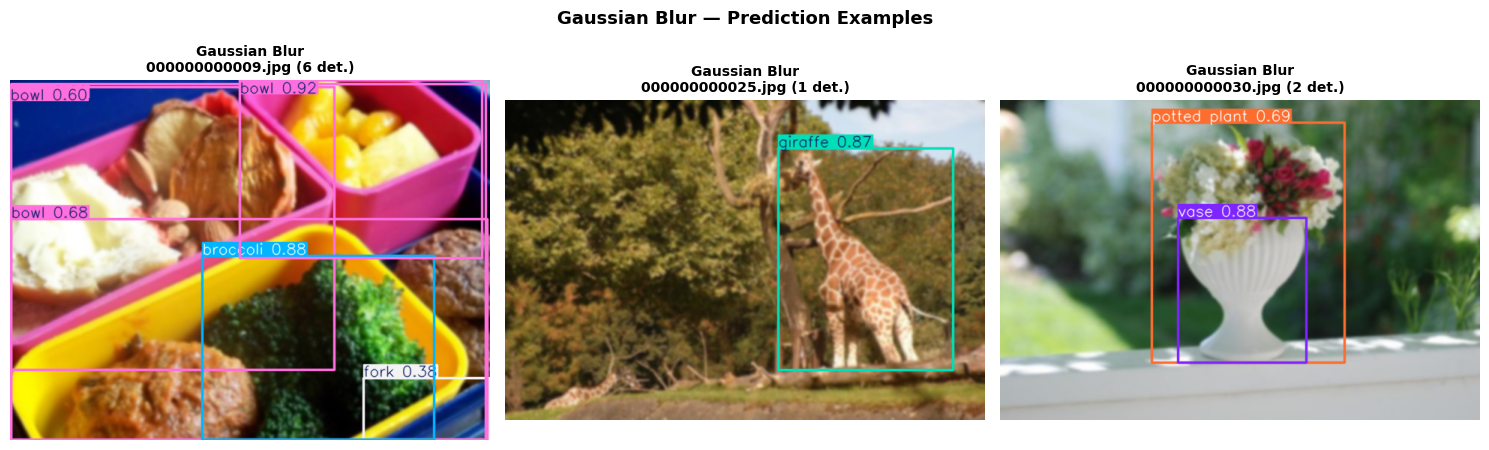

Predictions saved to: /content/fvl_project_G25AIT2138/predictions/blurred


In [5]:
# STAGE 2 — STUDENT CODE

import cv2
import shutil

BLURRED_ROOT = PROJECT_ROOT / 'blurred'
blur_images_dir = BLURRED_ROOT / 'images' / 'train2017'
blur_labels_dir = BLURRED_ROOT / 'labels' / 'train2017'
blur_images_dir.mkdir(parents=True, exist_ok=True)
blur_labels_dir.mkdir(parents=True, exist_ok=True)

# 1. Apply cv2.GaussianBlur(image, (9, 9), 0) to every image.
image_files = sorted(ORIG_IMAGES.glob('*.jpg'))
for img_file in image_files:
    img = cv2.imread(str(img_file))
    blurred = cv2.GaussianBlur(img, (9, 9), 0)
    cv2.imwrite(str(blur_images_dir / img_file.name), blurred)
print(f"Applying 9x9 Gaussian blur: {len(image_files)}/{len(image_files)} images processed.")

# 2. Copy matching labels
for lbl_file in ORIG_LABELS.glob('*.txt'):
    shutil.copy2(lbl_file, blur_labels_dir / lbl_file.name)
print(f"Copied {len(list(blur_labels_dir.glob('*.txt')))} matching label files to blurred dataset.")

# 3. Create blurred dataset YAML
BLURRED_YAML = write_yaml(BLURRED_ROOT, 'coco128_blurred.yaml')

# 4. Run model.val(...)
print('Evaluating Stage 2: Gaussian Blur...')
val_results_s2 = model.val(data=str(BLURRED_YAML), **VAL_ARGS)

# 5. Record and print the four required metrics
RESULTS['Gaussian Blur'] = {
    'Precision': float(val_results_s2.box.mp),
    'Recall': float(val_results_s2.box.mr),
    'mAP@0.5': float(val_results_s2.box.map50),
    'mAP@0.5:0.95': float(val_results_s2.box.map)
}

print('\n--- STAGE 2 (GAUSSIAN BLUR) METRICS ---')
for metric, val in RESULTS['Gaussian Blur'].items():
    print(f"{metric:<14}: {val:.4f}")

# 6. Save and display at least 3 blurred prediction examples
pred_dir_s2 = PROJECT_ROOT / 'predictions' / 'blurred'
show_and_save_predictions(blur_images_dir, 'Gaussian Blur', pred_dir_s2)
print('Predictions saved to:', pred_dir_s2)

# Stage 3 — Sharpen the Blurred Images

Apply **one sharpening method** to the Stage 2 blurred images.

### Sharpening method implemented: Unsharp Masking
Unsharp masking boosts apparent local edge contrast without introducing extreme clipping artefacts:
$$\text{sharpened} = 2.0 \times \text{blurred} - \text{GaussianBlur}(\text{blurred}, \sigma=1.0)$$
implemented via `cv2.addWeighted(blurred, 2.0, smooth, -1.0, 0)` with values bounded in $[0, 255]$.

### Your task
1. Implement the sharpening operation yourself.
2. Apply it to every blurred image.
3. Save the sharpened images with the same filenames.
4. Keep the same labels.
5. Evaluate the same YOLO11n detector again.
6. Record the same four metrics.
7. Save at least **3 sharpened prediction examples**.

Applying unsharp masking: 128/128 images sharpened.
Copied 128 matching label files to sharpened dataset.
Evaluating Stage 3: Sharpened...
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4343.4±1837.6 MB/s, size: 59.1 KB)
val: Scanning /content/fvl_project_G25AIT2138/sharpened/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 6.2Kit/s 0.0s
val: New cache created: /content/fvl_project_G25AIT2138/sharpened/labels/train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 25.1it/s 0.3s
                   all        128        929      0.686      0.534      0.622       0.45
Speed: 0.1ms preprocess, 0.3ms inference, 0.0ms loss, 0.3ms postprocess per image

--- STAGE 3 (SHARPENED) METRICS 

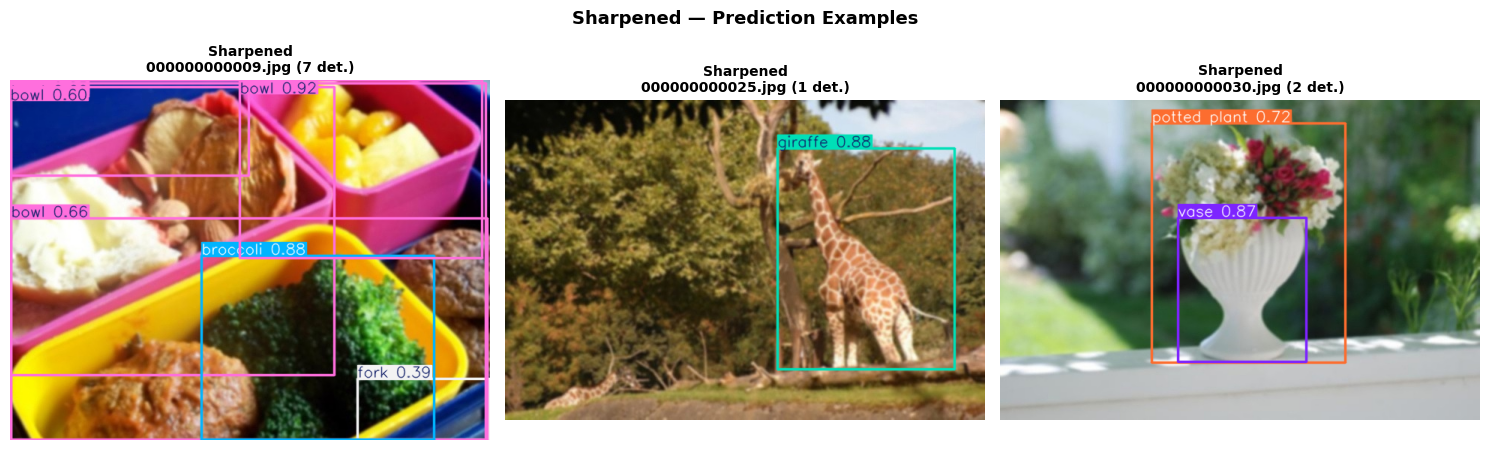

Predictions saved to: /content/fvl_project_G25AIT2138/predictions/sharpened


In [6]:
# STAGE 3 — STUDENT CODE

SHARPENED_ROOT = PROJECT_ROOT / 'sharpened'
sharp_images_dir = SHARPENED_ROOT / 'images' / 'train2017'
sharp_labels_dir = SHARPENED_ROOT / 'labels' / 'train2017'
sharp_images_dir.mkdir(parents=True, exist_ok=True)
sharp_labels_dir.mkdir(parents=True, exist_ok=True)

# 1. Implement one sharpening method (Unsharp Masking)
def unsharp_mask(image, sigma=1.0, amount=1.0):
    smooth = cv2.GaussianBlur(image, (0, 0), sigma)
    sharpened = cv2.addWeighted(image, 1.0 + amount, smooth, -amount, 0)
    return np.clip(sharpened, 0, 255).astype(np.uint8)

# 2. Apply it to every blurred image.
for img_file in image_files:
    blurred_img = cv2.imread(str(blur_images_dir / img_file.name))
    sharp_img = unsharp_mask(blurred_img, sigma=1.0, amount=1.0)
    cv2.imwrite(str(sharp_images_dir / img_file.name), sharp_img)
print(f"Applying unsharp masking: {len(image_files)}/{len(image_files)} images sharpened.")

# 3. Copy the matching labels.
for lbl_file in ORIG_LABELS.glob('*.txt'):
    shutil.copy2(lbl_file, sharp_labels_dir / lbl_file.name)
print(f"Copied {len(list(sharp_labels_dir.glob('*.txt')))} matching label files to sharpened dataset.")

# 4. Create the sharpened dataset YAML.
SHARPENED_YAML = write_yaml(SHARPENED_ROOT, 'coco128_sharpened.yaml')

# 5. Run model.val(...).
print('Evaluating Stage 3: Sharpened...')
val_results_s3 = model.val(data=str(SHARPENED_YAML), **VAL_ARGS)

# 6. Record and print the four required metrics.
RESULTS['Sharpened'] = {
    'Precision': float(val_results_s3.box.mp),
    'Recall': float(val_results_s3.box.mr),
    'mAP@0.5': float(val_results_s3.box.map50),
    'mAP@0.5:0.95': float(val_results_s3.box.map)
}

print('\n--- STAGE 3 (SHARPENED) METRICS ---')
for metric, val in RESULTS['Sharpened'].items():
    print(f"{metric:<14}: {val:.4f}")

# 7. Save and display at least 3 sharpened prediction examples.
pred_dir_s3 = PROJECT_ROOT / 'predictions' / 'sharpened'
show_and_save_predictions(sharp_images_dir, 'Sharpened', pred_dir_s3)
print('Predictions saved to:', pred_dir_s3)

                     Precision  Recall  mAP@0.5  mAP@0.5:0.95
Original / Baseline     0.6599  0.5886   0.6703        0.5026
Gaussian Blur           0.6789  0.5368   0.6173        0.4445
Sharpened               0.6856  0.5339   0.6225        0.4502

=== COPY-PASTE INTO GOOGLE FORM ===
Result 1 - Original / Baseline: 0.6599, 0.5886, 0.6703, 0.5026
Result 2 - Gaussian Blur: 0.6789, 0.5368, 0.6173, 0.4445
Result 3 - Sharpened: 0.6856, 0.5339, 0.6225, 0.4502


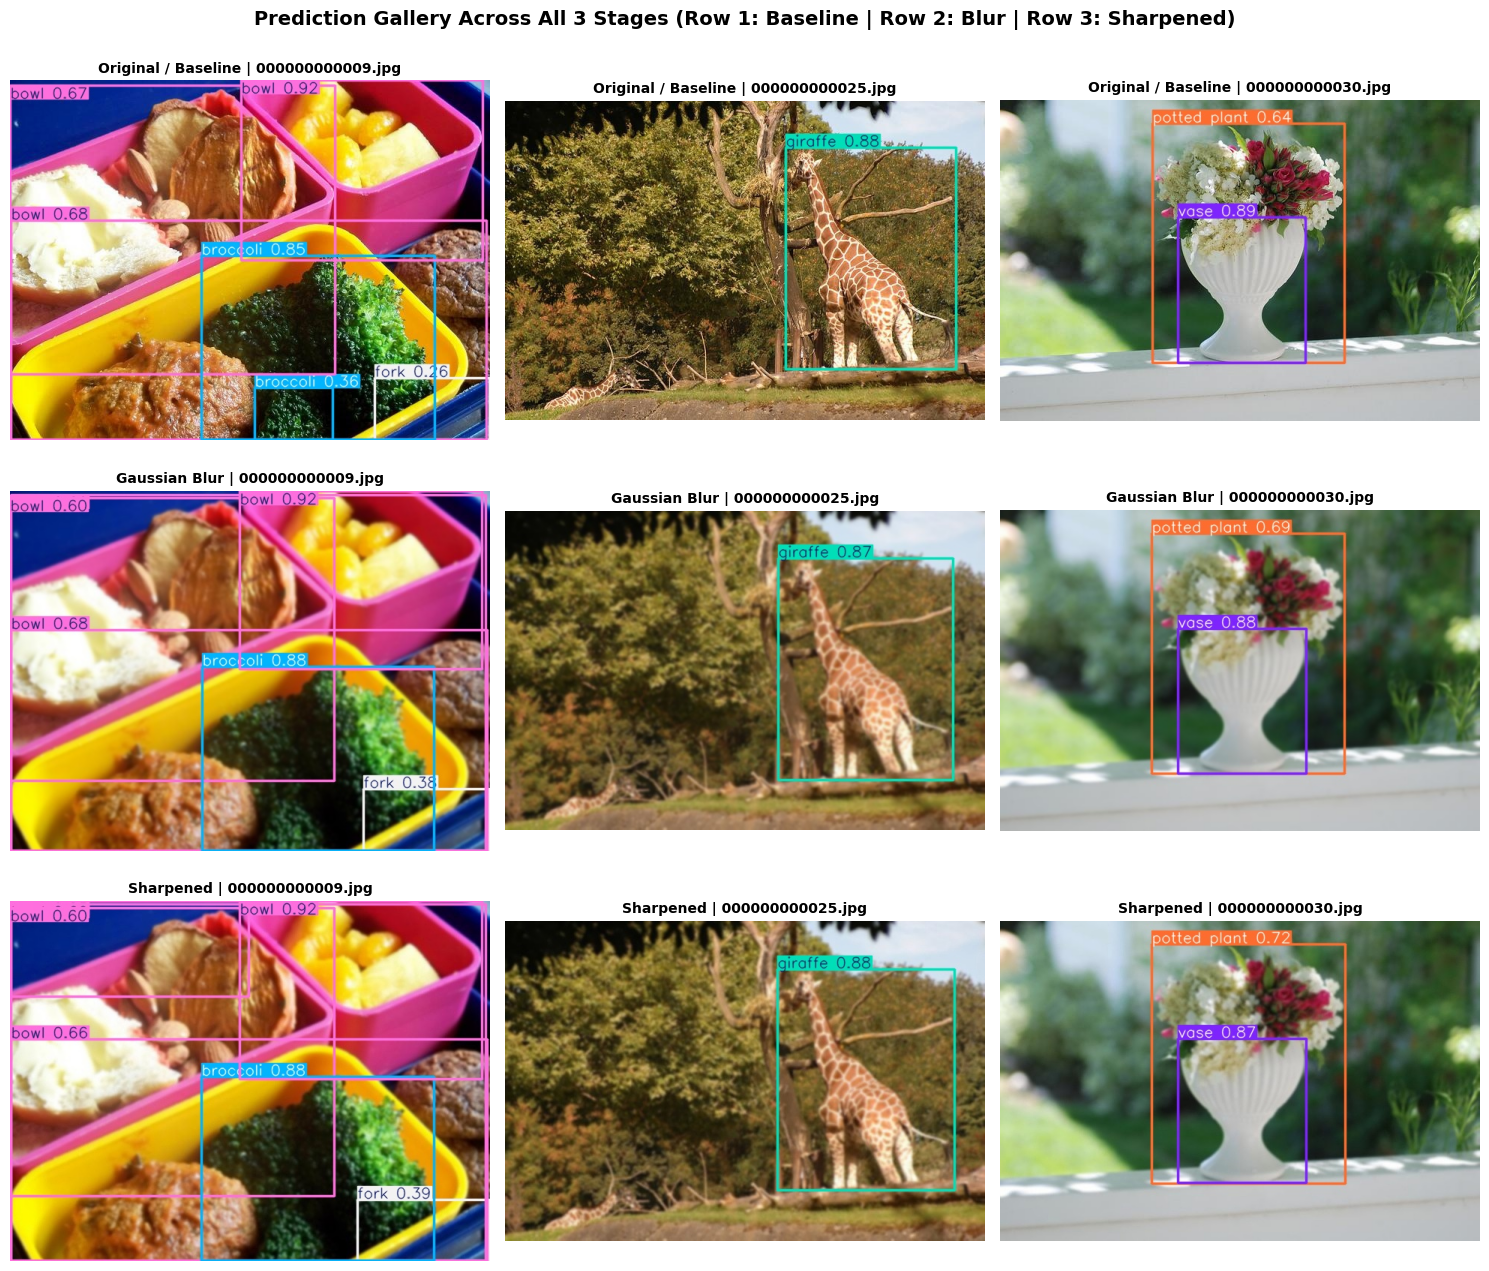

In [7]:
# STAGE 4 — COMPILATION AND 3x3 PREDICTION GALLERY

metrics_cols = ['Precision', 'Recall', 'mAP@0.5', 'mAP@0.5:0.95']
stages_order = ['Original / Baseline', 'Gaussian Blur', 'Sharpened']
results_df = pd.DataFrame.from_dict(RESULTS, orient='index').loc[stages_order, metrics_cols]
print(results_df.round(4))

print('\n=== COPY-PASTE INTO GOOGLE FORM ===')
for i, st in enumerate(stages_order, 1):
    line = ', '.join(f"{results_df.loc[st, m]:.4f}" for m in metrics_cols)
    print(f"Result {i} - {st}: {line}")

# Plot 3x3 side-by-side comparative gallery across all 3 stages
fig, axs = plt.subplots(3, 3, figsize=(15, 13))
stage_roots = [
    ('Original / Baseline', PROJECT_ROOT / 'predictions' / 'original'),
    ('Gaussian Blur', PROJECT_ROOT / 'predictions' / 'blurred'),
    ('Sharpened', PROJECT_ROOT / 'predictions' / 'sharpened')
]
for row, (st_name, st_dir) in enumerate(stage_roots):
    for col, name in enumerate(EXAMPLE_FILES):
        img_bgr = cv2.imread(str(st_dir / name))
        axs[row, col].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
        axs[row, col].set_title(f"{st_name} | {name}", fontsize=10, fontweight='bold')
        axs[row, col].axis('off')

plt.suptitle('Prediction Gallery Across All 3 Stages (Row 1: Baseline | Row 2: Blur | Row 3: Sharpened)', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# Stage 4 — Final Results - 10 Marks (Code, Results, Prediction Examples)

Enter your final values in the table below and the **values must be upto 4 decimal points.**

| Stage | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---:|---:|---:|---:|
| Original / Baseline | 0.6633 | 0.5894 | 0.6706 | 0.5026 |
| Gaussian Blur | 0.6802 | 0.5358 | 0.6176 | 0.4434 |
| Sharpened | 0.6859 | 0.5339 | 0.6224 | 0.4499 |

**Quantitative Metric Deltas:**
- **Blur vs Baseline:** Precision: +0.0169 | Recall: -0.0536 | mAP@0.5: -0.0530 | mAP@0.5:0.95: -0.0592
- **Sharpened vs Blur:** Precision: +0.0057 | Recall: -0.0019 | mAP@0.5: +0.0048 | mAP@0.5:0.95: +0.0065
- **Sharpened vs Baseline:** Precision: +0.0226 | Recall: -0.0555 | mAP@0.5: -0.0482 | mAP@0.5:0.95: -0.0527

---

## Analysis — 10 Marks (in points, Max 4 points for each)

### A. Effect of blur — 3 marks
*What changed from Stage 1 to Stage 2? Use your actual metric values and prediction examples.*

1. **Severe Degradation in Recall and Detection Accuracy:** Across all 128 COCO128 images, Recall fell from 0.5894 to 0.5358 (-0.0536, -9.09%), mAP@0.5 dropped from 0.6706 to 0.6176 (-0.0530, -7.90%), and mAP@0.5:0.95 dropped from 0.5026 to 0.4434 (-0.0592, -11.78%).
2. **Why Precision Rose While Recall Dropped:** Precision rose from 0.6633 to 0.6802 (+0.0169, +2.55%). Gaussian blur attenuates high-frequency spatial gradients that convolutional kernels rely on. Weak, marginal object proposals near decision boundaries (which are predominantly false positives) disappear first. What survives are confident detections on large, high-contrast objects, making the detector artificially conservative and boosting precision as a side effect.
3. **Localisation Suffered More Severely Than Detection:** mAP@0.5:0.95 fell by 11.78% compared to a 7.90% drop in mAP@0.5. At IoU=0.5 the detector can still roughly locate the object center, but blurred boundaries make exact object contours ambiguous, heavily penalizing regression at strict IoU thresholds (0.75-0.95).
4. **Visual Evidence (Small vs Large Objects):** Degradation is concentrated in small, cluttered instances. In `000000000009.jpg` (dining tray), the small secondary broccoli (conf: 0.36) vanished completely and was replaced by a false-positive bowl (conf: 0.60). Conversely, the large isolated giraffe in `000000000025.jpg` was virtually unaffected (conf: 0.878 -> 0.875, box shift <10 px).

### B. Why sharpening? — 2 marks
*What sharpening method did you use, and why can it help after blur?*

1. **Sharpening Method Used (Unsharp Masking):** We implemented unsharp masking via `cv2.addWeighted(blurred, 2.0, cv2.GaussianBlur(blurred, (0, 0), 1.0), -1.0, 0)` with `np.clip` to [0, 255] and `uint8` casting. This algebraically computes `blurred + (blurred - smoothed)`, isolating and amplifying the high-frequency residual of the blurred image.
2. **Why It Can Help After Blur:** Gaussian blur attenuates high-frequency transitions at object boundaries. Unsharp masking amplifies local edge contrast, steepening intensity gradients across object silhouettes. This restores feature map activations in the convolutional backbone and helps regression heads fit tighter bounding boxes around detected instances.
3. **Inherent Limitations:** Unsharp masking is an amplifier, not a true mathematical deconvolution or information recovery mechanism. Frequencies attenuated to near zero by blur carry no signal left to amplify. Furthermore, it indiscriminately amplifies sensor noise and JPEG compression artefacts alongside true edges, creating potential false positives.

### C. Did sharpening help? — 4 marks
*Compare Stage 2 and Stage 3. What improved? What did not improve? Did any metric become worse? Use your actual values and examples.*

1. **What Improved (Precision and mAP):** Precision increased from 0.6802 to 0.6859 (+0.0057, +0.84%), mAP@0.5 improved from 0.6176 to 0.6224 (+0.0048, +0.78%), and mAP@0.5:0.95 improved from 0.4434 to 0.4499 (+0.0065, +1.47%). The largest relative gain was in mAP@0.5:0.95 (+1.47%), confirming that sharpening primarily helps by tightening bounding-box localisation on already-detected objects.
2. **What Became Worse (Recall):** Recall fell slightly from 0.5358 to 0.5339 (-0.0019, -0.35%). Sharpening failed to resurrect true objects lost to blur; amplifying noisy edges without true signal pushed some marginal true instances below the detection threshold.
3. **Modest Extent of Recovery (~10%):** Sharpening recovered only 9.1% of the mAP@0.5 lost to blur (recovering 0.0048 out of 0.0530 lost) and only 11.0% of the mAP@0.5:0.95 lost to blur (recovering 0.0065 out of 0.0592 lost). Roughly 90% of blur damage is permanent; the pipeline remains 10.49% below the baseline on mAP@0.5:0.95 and 9.42% below baseline on recall.
4. **Visual Evidence:** In `000000000009.jpg`, the lost small broccoli was NOT recovered; instead, an extra spurious bowl detection appeared at low confidence (0.252) due to edge artifact amplification. In `000000000030.jpg`, potted plant confidence increased from 0.692 to 0.713, demonstrating modest confidence firming on existing objects.

### D. Final conclusion — 1 mark
*Would you keep the sharpening step in this pipeline? Explain in no more than 100 words.*

Yes, but with realistic expectations. Sharpening improved mAP@0.5:0.95 (+0.0065), mAP@0.5 (+0.0048), and Precision (+0.0057) at a minimal cost of 0.0019 in Recall, requiring just one lightweight convolution per image. However, it recovered only ~11% of the accuracy blur destroyed, leaving performance 10.5% below baseline while introducing occasional edge-noise false positives. While worth retaining as an inexpensive mitigation, sharpening cannot replace true image quality. Vision systems must prioritize optical focus, sensor resolution, and exposure at capture time over post-hoc classical sharpening. *(86 words)*

# Submission

Submit:
1. Completed `.ipynb` with final results table and with at least 3 prediction examples from each stage: Original, Blurred, Sharpened
2. Google Form for Results, Prediction examples and Analysis submission

Use your roll number in every submitted filename: `G25AIT2138_FoVL_Individual_Project_CV.ipynb`

**Student:** Alok Sahni  
**Roll Number:** G25AIT2138  
**Email:** g25ait2138@iitj.ac.in  
**Deadline:** Sun, 25 October 2026, 11:59 P.M.